# Pertemuan 12 — Penyiapan Data

**Proyek Akhir Pembelajaran Mesin (INF62325) · Cabang C — Klastering K-Means**
**S1 Informatika · UIN Siber Syekh Nurjati Cirebon**

| | |
|---|---|
| Dikerjakan oleh | kelompok, **satu kali saja** |
| Berkas yang dibutuhkan | akun Kaggle (untuk `kagglehub`) dan akun Google (untuk folder Drive kelompok) |
| Luaran wajib | `data/raw.csv`, `data/data_bersih.csv`, dua gambar EDA, empat jawaban EDA — semuanya di folder Drive kelompok |
| Dinilai pada | Progres 1, Pertemuan 12, **20%** (nilai kelompok) |
| Tenggat | `data_bersih.csv` harus jadi sebelum Pertemuan 13 |

| | |
|---|---|
| Kelompok | Kelompok 4 (Kelas 5B) |
| Paket dataset | 5B-4 — IBM HR Employee Attrition |
| Nama dan NIM | 1. Noval Adrian (2488010018) — Varian 1 (Elbow)<br>2. Faqih Huddin SM. (2488010061) — Varian 2 (Silhouette)<br>3. Irfan Mubarok (2488010075) — Varian 3 (Davies-Bouldin) |

---

## Cara memakai notebook ini

1. **File → Save a copy in Drive** lebih dulu. Tanpa itu isian Anda pada notebook tidak tersimpan.
2. Jalankan **Bagian 0 Persiapan** setiap kali notebook dibuka. Sel pertamanya menghubungkan folder Drive kelompok, yaitu `MyDrive/ProyekML_KlasteringKMeans`, dan folder itulah yang dibaca lagi oleh notebook Pertemuan 13, 14, dan 15.
3. Setelah sel pertama bagian 0 selesai dijalankan oleh pemilik folder, bagikan folder `ProyekML_KlasteringKMeans` kepada kedua anggota lain dengan akses **Editor**.
4. Kerjakan bagian 1.1 sampai 1.9 berurutan.
5. Panduan lengkapnya ada di dokumen **Manual Pertemuan 12**.

Bagian ini **dikerjakan satu kali oleh kelompok**, bukan tiga kali. Hasilnya, `data_bersih.csv`, dipakai ketiga anggota apa adanya. Kalau tiap anggota membersihkan data sendiri-sendiri, ketiga varian berjalan di atas data yang berbeda dan tabel perbandingan di Pertemuan 13 kehilangan maknanya.

---

## 0. Persiapan — **jalankan setiap kali notebook dibuka**

Sesi Colab menghapus seluruh berkasnya setiap kali runtime dimulai ulang. Karena itu hasil kerja tidak disimpan di sesi Colab, melainkan di **satu folder Google Drive** yang dipakai bersama sepanjang Pertemuan 12 sampai 15. Empat sel di bawah menghubungkan folder itu, memasang pustaka, menulis `alat.py`, dan menyiapkan fungsi pembantu. Keempatnya dijalankan lebih dulu, apa pun bagian yang Anda kerjakan di notebook ini.

`alat.py` berisi fungsi yang dipakai ketiga varian. **Jangan mengubahnya sendiri-sendiri:** kalau satu anggota mengubah isi berkas ini, ketiga varian berhenti sebanding dan tabel perbandingan menjadi tidak sah.

In [12]:
# Folder Drive ini adalah tempat serah-terima antar pertemuan: apa pun yang
# ditulis di sini terbaca kembali oleh notebook pertemuan berikutnya.
import os
import sys
from google.colab import drive

drive.mount('/content/drive')

FOLDER = '/content/drive/MyDrive/ProyekML_KlasteringKMeans'
os.makedirs(FOLDER, exist_ok=True)
os.chdir(FOLDER)      # sejak baris ini, 'data/...' berarti di dalam FOLDER

if FOLDER not in sys.path:
    sys.path.insert(0, FOLDER)   # agar 'import alat' menemukan berkas di folder ini

for d in ('data', 'data/hasil_varian', 'model', 'gambar'):
    os.makedirs(d, exist_ok=True)

print('Folder proyek:', FOLDER)
print('Isi folder   :', sorted(os.listdir()) or '(masih kosong)')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Folder proyek: /content/drive/MyDrive/ProyekML_KlasteringKMeans
Isi folder   : ['__pycache__', 'alat.py', 'data', 'gambar', 'model']


In [13]:
import ast, json, os, shutil, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib, sklearn

warnings.filterwarnings('ignore')
pd.set_option('display.width', 170)
pd.set_option('display.max_columns', 40)

SEED = 42
ID_COL = 'EmployeeNumber'     # kolom identitas dataset IBM HR Employee Attrition
IQR_PENGALI = 1.5

# 12 fitur kandidat segmentasi sesuai proposal Kelompok 4 (11 numerik/ordinal + 1 biner)
FITUR_KANDIDAT = [
    'Age', 'MonthlyIncome', 'TotalWorkingYears', 'YearsAtCompany',
    'YearsSinceLastPromotion', 'NumCompaniesWorked', 'DistanceFromHome',
    'JobSatisfaction', 'EnvironmentSatisfaction', 'WorkLifeBalance',
    'JobInvolvement', 'OverTime_Yes',
]

print('Siap. scikit-learn', sklearn.__version__)
print('Catat versi ini. Angka yang sama nanti ditulis di requirements.txt.')

Siap. scikit-learn 1.6.1
Catat versi ini. Angka yang sama nanti ditulis di requirements.txt.


In [14]:
%%writefile alat.py
"""alat.py -- fungsi bersama ketiga varian. Jangan diubah sendiri-sendiri."""
from __future__ import annotations

import json
import os

import numpy as np
import pandas as pd
from sklearn.cluster import KMeans
from sklearn.metrics import (calinski_harabasz_score,
                             davies_bouldin_score, silhouette_score)
from sklearn.preprocessing import StandardScaler

SEED = 42
ID_COL = 'EmployeeNumber'
RENTANG_K = range(2, 11)
BERKAS_BERSIH = 'data/data_bersih.csv'
FOLDER_HASIL = 'data/hasil_varian'

# Label dan satuan untuk antarmuka aplikasi (ketentuan Tahap 3: setiap
# masukan harus punya label dan satuan yang dipahami orang luar).
LABEL = {
    'Age': ('Usia karyawan', 'tahun'),
    'MonthlyIncome': ('Pendapatan bulanan', 'satuan moneter dataset'),
    'TotalWorkingYears': ('Total pengalaman kerja', 'tahun'),
    'YearsAtCompany': ('Lama bekerja di perusahaan', 'tahun'),
    'YearsSinceLastPromotion': ('Lama sejak promosi terakhir', 'tahun'),
    'NumCompaniesWorked': ('Jumlah perusahaan tempat bekerja', 'perusahaan'),
    'DistanceFromHome': ('Jarak rumah ke kantor', 'satuan jarak dataset'),
    'JobSatisfaction': ('Kepuasan kerja', 'skor 1-4'),
    'EnvironmentSatisfaction': ('Kepuasan lingkungan kerja', 'skor 1-4'),
    'WorkLifeBalance': ('Keseimbangan kerja-kehidupan', 'skor 1-4'),
    'JobInvolvement': ('Keterlibatan kerja', 'skor 1-4'),
    'OverTime_Yes': ('Status lembur (0=Tidak, 1=Ya)', '0 atau 1'),
}


def label_satuan(kolom: str) -> tuple[str, str]:
    return LABEL.get(kolom, (kolom.replace('_', ' ').title(), ''))


def muat_bersih(fitur: list[str] | None = None) -> pd.DataFrame:
    """Membaca data bersih kelompok. Kolom identitas selalu dibuang."""
    df = pd.read_csv(BERKAS_BERSIH)
    # Pengaman ganda: buang kolom identitas secara eksplisit meskipun bertipe numerik.
    df = df.drop(columns=[ID_COL], errors='ignore')
    df = df.select_dtypes(include='number')
    return df[fitur] if fitur else df


def skalakan(df: pd.DataFrame):
    sc = StandardScaler()
    return sc.fit_transform(df), sc


def jalankan_k(X_scaled, rentang=RENTANG_K) -> pd.DataFrame:
    """Menjalankan K-Means untuk tiap k, mengembalikan tabel metrik."""
    baris = []
    for k in rentang:
        km = KMeans(n_clusters=k, init='k-means++', n_init=20,
                    random_state=SEED)
        lab = km.fit_predict(X_scaled)
        baris.append({
            'k': k,
            'inertia': float(km.inertia_),
            'silhouette': float(silhouette_score(X_scaled, lab)),
            'davies_bouldin': float(davies_bouldin_score(X_scaled, lab)),
            'calinski_harabasz': float(calinski_harabasz_score(X_scaled, lab)),
        })
    return pd.DataFrame(baris)


def titik_siku(ks, inertia) -> int:
    """Titik siku = jarak tegak lurus terjauh dari garis ujung ke ujung."""
    x = np.asarray(ks, dtype=float)
    y = np.asarray(inertia, dtype=float)
    x_n = (x - x.min()) / (x.max() - x.min())
    y_n = (y - y.min()) / (y.max() - y.min())
    x1, y1, x2, y2 = x_n[0], y_n[0], x_n[-1], y_n[-1]
    jarak = np.abs((y2 - y1) * x_n - (x2 - x1) * y_n + x2 * y1 - y2 * x1)
    jarak /= np.hypot(y2 - y1, x2 - x1)
    return int(x[int(np.argmax(jarak))])


def profil_relatif(df: pd.DataFrame, label) -> pd.DataFrame:
    """Simpangan rata-rata tiap klaster terhadap rata-rata seluruh data,
    dalam satuan simpangan baku. Baris = fitur, kolom = klaster."""
    d = df.copy()
    d['cluster'] = label
    rata = d.drop(columns='cluster').mean()
    sd = d.drop(columns='cluster').std().replace(0, np.nan)
    return ((d.groupby('cluster').mean() - rata) / sd).round(2).T


def nama_otomatis(profil: pd.DataFrame) -> dict[str, str]:
    """Dua fitur dengan simpangan terbesar secara mutlak, beserta arahnya.
    WAJIB diganti mahasiswa dengan nama yang bermakna."""
    nama = {}
    for c in profil.columns:
        kol = profil[c]
        kuat = kol.reindex(kol.abs().sort_values(ascending=False).index)[:2]
        nama[str(int(c))] = ', '.join(
            f'{n} {"tinggi" if v > 0 else "rendah"}' for n, v in kuat.items())
    return nama


def simpan_hasil(nomor: int, isi: dict) -> str:
    os.makedirs(FOLDER_HASIL, exist_ok=True)
    jalur = f'{FOLDER_HASIL}/varian{nomor}.json'
    with open(jalur, 'w', encoding='utf-8') as f:
        json.dump(isi, f, indent=2, ensure_ascii=False)
    return jalur


def baca_hasil(nomor: int) -> dict | None:
    jalur = f'{FOLDER_HASIL}/varian{nomor}.json'
    if not os.path.exists(jalur):
        return None
    with open(jalur, encoding='utf-8') as f:
        return json.load(f)

Overwriting alat.py


In [15]:
def ambil_berkas():
    """Cadangan: unggah berkas manual bila folder Drive tak bisa diakses."""
    from google.colab import files
    for nama in files.upload():
        if nama.startswith('varian') and nama.endswith('.json'):
            tujuan = 'data/hasil_varian/' + nama
        elif nama.endswith('.pkl') or nama == 'segmen.json':
            tujuan = 'model/' + nama
        elif nama.endswith('.png'):
            tujuan = 'gambar/' + nama
        else:
            tujuan = 'data/' + nama
        shutil.move(nama, tujuan)
        print('->', tujuan)


def perlu(*jalur):
    """Memastikan luaran pertemuan sebelumnya sudah ada di folder Drive."""
    kurang = [j for j in jalur if not os.path.exists(j)]
    if not kurang:
        print('Lengkap:', ', '.join(jalur))
        return
    raise FileNotFoundError(
        'Belum ada di folder Drive: ' + ', '.join(kurang) + '. '
        'Jalankan notebook pertemuan sebelumnya sampai selesai. Bila folder '
        'kelompok tidak dapat diakses dari akun Google Anda, jalankan '
        'ambil_berkas() di sel baru untuk mengunggah berkasnya manual.')


print('Folder kerja:', os.getcwd())
print('perlu() dan ambil_berkas() siap dipakai.')

Folder kerja: /content/drive/MyDrive/ProyekML_KlasteringKMeans
perlu() dan ambil_berkas() siap dipakai.


# Bagian 1 — Penyiapan Data

**Proyek Akhir Pembelajaran Mesin (INF62325) · Cabang C — Klastering K-Means**
**S1 Informatika · UIN Siber Syekh Nurjati Cirebon**

| | |
|---|---|
| Pertemuan | Pertemuan 12 (Progres 1) |
| Tahap resmi | Tahap 1 — Penyiapan Data |
| Dikerjakan oleh | kelompok, **sekali saja** |
| Berkas yang dibutuhkan | akun Kaggle (untuk `kagglehub`) dan akun Google (untuk folder Drive kelompok) |
| Luaran wajib | `data/raw.csv`, `data/data_bersih.csv`, dua gambar EDA, dan empat jawaban EDA — semuanya di folder Drive kelompok |
| Dinilai pada | Progres 1, Pertemuan 12, **20%** (nilai kelompok) |
| Tenggat | `data_bersih.csv` harus jadi sebelum Pertemuan 13 |

| | |
|---|---|
| Kelompok | Kelompok 4 (Kelas 5B) |
| Paket dataset | 5B-4 — IBM HR Employee Attrition |
| Nama dan NIM | 1. Noval Adrian (2488010018)<br>2. Faqih Huddin SM. (2488010061)<br>3. Irfan Mubarok (2488010075) |

---

## Panduan Bagian 1

Bagian ini **dikerjakan satu kali oleh kelompok**, bukan tiga kali. Hasilnya, `data_bersih.csv`, dipakai ketiga anggota apa adanya. Kalau tiap anggota membersihkan data sendiri-sendiri, ketiga varian berjalan di atas data yang berbeda dan tabel perbandingan di Bagian 5 kehilangan maknanya.

**Urutan kerja**

1. Jalankan Bagian 0 (persiapan).
2. Jalankan 1.1 untuk mengunduh dataset dari Kaggle lewat `kagglehub`.
3. Jalankan 1.2 agar berkas terbaca dan salinan asli tersimpan sebagai `raw.csv`.
4. Jalankan 1.3 sampai 1.5 untuk eksplorasi data.
5. Periksa dan pastikan keempat jawaban di 1.6 sudah sesuai dengan hasil eksekusi.
6. Jalankan 1.7 dan 1.8 untuk membersihkan dan menyimpan data.
7. Salin pernyataan urutan kerja di 1.9 ke `README.md` setelah diperiksa kebenarannya.
8. Commit `data_bersih.csv`, `raw.csv`, dua gambar EDA, dan notebook ini (`01_penyiapan_data.ipynb`) ke repositori kelompok.

**Yang perlu dipahami lebih dulu**

Pada klastering **tidak ada pemisahan data latih dan data uji**, karena tidak ada label yang diuji. Jadi pembersihan dilakukan sekali atas seluruh data. Yang dijaga bukan kebocoran antar-himpunan, melainkan kesamaan perlakuan antara notebook dan aplikasi web nanti.

**Yang dinilai pada Progres 1**

Kelompok diminta menjelaskan, lima menit, apa satu baris data itu, kolom apa yang dibuang dan mengapa, serta berapa nilai yang diimputasi dan dibatasi. Angka-angka itu muncul di keluaran sel, jadi jangan hanya menjalankan sel lalu menutup notebook.

---

## 1.1 Mengunduh dataset dari Kaggle dengan `kagglehub`

Dataset diunduh oleh notebook sendiri, bukan diunggah manual. Alasannya: notebook yang mengunduh datanya sendiri dapat dijalankan ulang oleh dosen maupun oleh anggota kelompok lain tanpa berkas titipan, sehingga angka yang Anda laporkan bisa diverifikasi.

`SLUG` adalah dua potongan terakhir URL halaman dataset di Kaggle:

```
https://www.kaggle.com/datasets/arjunbhasin2013/ccdata
                                └────────  SLUG  ──────┘
```

Jadi untuk URL di atas, `SLUG = 'arjunbhasin2013/ccdata'`. Ganti nilainya sesuai dataset yang kelompok Anda pilih.

Yang perlu diingat: `dataset_download` mengembalikan **path folder**, bukan DataFrame. Karena itu isi foldernya dicetak lebih dulu, baru berkas CSV-nya dibaca di 1.2. Bila dataset bersifat privat atau menuntut persetujuan kompetisi, `kagglehub` akan meminta token Kaggle Anda (*Settings → API → Create New Token*).

In [16]:
# kagglehub sudah tersedia di Colab. Bila belum, hapus tanda pagar di bawah.
# !pip install -q kagglehub

import kagglehub

SLUG = 'pavansubhasht/ibm-hr-analytics-attrition-dataset'

unduhan = kagglehub.dataset_download(SLUG)   # mengembalikan path FOLDER
print('Folder unduhan:', unduhan)

# Beberapa dataset menaruh CSV-nya di dalam subfolder, jadi dicari menyeluruh.
semua_csv = sorted(os.path.join(akar, f)
                   for akar, _, berkas in os.walk(unduhan)
                   for f in berkas if f.endswith('.csv'))
print('Berkas CSV yang ditemukan:')
for i, j in enumerate(semua_csv):
    print(' ', i, '->', os.path.basename(j))

Using Colab cache for faster access to the 'ibm-hr-analytics-attrition-dataset' dataset.
Folder unduhan: /kaggle/input/ibm-hr-analytics-attrition-dataset
Berkas CSV yang ditemukan:
  0 -> WA_Fn-UseC_-HR-Employee-Attrition.csv


## 1.2 Membaca data dan menyimpan salinan asli

Keluaran sel 1.1 bernomor mulai dari 0. Bila berkas yang benar bukan yang bernomor 0, ubah angka pada `semua_csv[0]` di bawah. Nama berkas Kaggle sering mengandung spasi, misalnya `CC GENERAL.csv`, dan itu tidak masalah karena jalurnya tidak ditulis tangan.

`raw.csv` adalah salinan mentah di folder Drive yang **tidak pernah diubah lagi**. Gunanya agar Anda selalu dapat kembali ke keadaan awal tanpa mengunduh ulang, dan agar dosen dapat memeriksa data yang persis Anda pakai.

In [17]:
BERKAS = semua_csv[0]            # ubah angkanya bila berkas yang benar bukan yang pertama
print('Membaca:', BERKAS)

# utf-8-sig mengatasi kemungkinan karakter BOM pada awal nama kolom pertama (Age).
df_mentah = pd.read_csv(BERKAS, encoding='utf-8-sig')
df_mentah.to_csv('data/raw.csv', index=False)   # salinan asli di Drive, jangan diubah lagi
print('Ukuran:', df_mentah.shape)
print('Kolom pertama:', df_mentah.columns[0])
df_mentah.head()

Membaca: /kaggle/input/ibm-hr-analytics-attrition-dataset/WA_Fn-UseC_-HR-Employee-Attrition.csv
Ukuran: (1470, 35)
Kolom pertama: Age


,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,EnvironmentSatisfaction,Gender,HourlyRate,JobInvolvement,JobLevel,JobRole,JobSatisfaction,MaritalStatus,MonthlyIncome,MonthlyRate,NumCompaniesWorked,Over18,OverTime,PercentSalaryHike,PerformanceRating,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,2,Female,94,3,2,Sales Executive,4,Single,5993,19479,8,Y,Yes,11,3,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,3,Male,61,2,2,Research Scientist,2,Married,5130,24907,1,Y,No,23,4,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,4,Male,92,2,1,Laboratory Technician,3,Single,2090,2396,6,Y,Yes,15,3,2,80,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,4,Female,56,3,1,Research Scientist,3,Married,2909,23159,1,Y,Yes,11,3,3,80,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,1,Male,40,3,1,Laboratory Technician,2,Married,3468,16632,9,Y,No,12,3,4,80,1,6,3,3,2,2,2,2


## 1.3 Bentuk data, nilai hilang, dan kolom identitas

Untuk klastering, perhatian diarahkan ke empat hal: **perbedaan skala antarfitur**, **korelasi tinggi** yang menandakan fitur kembar, **pencilan**, dan **kolom identitas**. Sel ini mengurus yang terakhir.

Kolom dengan jumlah nilai unik hampir sama dengan jumlah baris hampir pasti kolom identitas. Kolom seperti itu harus dibuang: nomor pelanggan tidak mengandung informasi perilaku, tetapi K-Means akan tetap memperlakukannya sebagai jarak.

In [18]:
df_mentah.info()

hilang = df_mentah.isna().sum()
hilang = hilang[hilang > 0]
print('\nNilai hilang:', 'tidak ada (0 sel)' if hilang.empty else '')
for c, n in hilang.items():
    print(f'  {c:<34} {n:>5}  ({n/len(df_mentah)*100:5.2f}%)')

print('\nBaris duplikat identik    :', int(df_mentah.duplicated().sum()))
print('EmployeeNumber berulang   :', int(df_mentah[ID_COL].duplicated().sum()))

unik = df_mentah.nunique(dropna=False)
print('\nKolom konstan (1 nilai unik):', unik[unik <= 1].index.tolist())

print('\nKolom dengan nilai unik > 90% baris (kandidat identitas):')
for c in unik[unik > 0.9 * len(df_mentah)].index:
    print(f'  {c:<25} -> {unik[c]} nilai unik dari {len(df_mentah)} baris (tipe: {df_mentah[c].dtype})')

print('\nKardinalitas kolom non-numerik:')
for c in df_mentah.select_dtypes(exclude=np.number).columns:
    print(f'  {c:<20} -> {df_mentah[c].nunique()} nilai unik -> {df_mentah[c].unique().tolist()[:5]}')

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1470 entries, 0 to 1469
Data columns (total 35 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   Age                       1470 non-null   int64 
 1   Attrition                 1470 non-null   object
 2   BusinessTravel            1470 non-null   object
 3   DailyRate                 1470 non-null   int64 
 4   Department                1470 non-null   object
 5   DistanceFromHome          1470 non-null   int64 
 6   Education                 1470 non-null   int64 
 7   EducationField            1470 non-null   object
 8   EmployeeCount             1470 non-null   int64 
 9   EmployeeNumber            1470 non-null   int64 
 10  EnvironmentSatisfaction   1470 non-null   int64 
 11  Gender                    1470 non-null   object
 12  HourlyRate                1470 non-null   int64 
 13  JobInvolvement            1470 non-null   int64 
 14  JobLevel                

## 1.4 Skala antarfitur

K-Means mengukur jarak Euclidean. Kalau satu kolom bersatuan rupiah dan kolom lain bernilai 0 sampai 1, kolom rupiah akan menentukan hampir seluruh jaraknya, dan kolom kedua praktis tidak dipakai. Karena itu penskalaan wajib.

Perhatikan kalimat terakhir keluaran sel ini. Scaler yang dipakai nanti **disimpan** dan dipakai aplikasi web dengan `transform`, bukan dihitung ulang di sana. Ini salah satu dari tiga aturan aplikasi yang diperiksa di Bagian 7.

In [19]:
# Susun 12 fitur kandidat sesuai proposal (11 numerik/ordinal + OverTime_Yes) untuk pemeriksaan skala
df_eda = df_mentah[[c for c in FITUR_KANDIDAT if c != 'OverTime_Yes']].copy()
df_eda['OverTime_Yes'] = (df_mentah['OverTime'] == 'Yes').astype(int)

ringkas = df_eda.describe().T[['min', 'mean', 'max']]
ringkas['std'] = df_eda.std()
ringkas['skew'] = df_eda.skew()
display(ringkas.round(2))

rasio_max = ringkas['max'].max() / max(ringkas['max'].abs().min(), 1e-9)
rasio_std = ringkas['std'].max() / max(ringkas['std'].min(), 1e-9)
print(f'Rasio nilai maksimum terbesar terhadap terkecil (12 fitur kandidat): {rasio_max:,.0f} kali.')
print(f'Rasio standar deviasi terbesar terhadap terkecil                   : {rasio_std:,.0f} kali.')
print('Karena itu penskalaan wajib. Scaler-nya nanti DISIMPAN untuk dipakai')
print('aplikasi web dengan transform, bukan dihitung ulang di sana.')

,min,mean,max,std,skew
Age,18.0,36.92,60.0,9.14,0.41
MonthlyIncome,1009.0,6502.93,19999.0,4707.96,1.37
TotalWorkingYears,0.0,11.28,40.0,7.78,1.12
YearsAtCompany,0.0,7.01,40.0,6.13,1.76
YearsSinceLastPromotion,0.0,2.19,15.0,3.22,1.98
NumCompaniesWorked,0.0,2.69,9.0,2.50,1.03
DistanceFromHome,1.0,9.19,29.0,8.11,0.96
JobSatisfaction,1.0,2.73,4.0,1.10,-0.33
EnvironmentSatisfaction,1.0,2.72,4.0,1.09,-0.32
WorkLifeBalance,1.0,2.76,4.0,0.71,-0.55


Rasio nilai maksimum terbesar terhadap terkecil (12 fitur kandidat): 19,999 kali.
Rasio standar deviasi terbesar terhadap terkecil                   : 10,448 kali.
Karena itu penskalaan wajib. Scaler-nya nanti DISIMPAN untuk dipakai
aplikasi web dengan transform, bukan dihitung ulang di sana.


## 1.5 Distribusi dan korelasi

Dua gambar yang dihasilkan sel ini wajib ada di folder `gambar/` dan dipakai di laporan.

Pasangan fitur dengan korelasi di atas 0,9 praktis mengukur hal yang sama. Bagi K-Means, dua fitur kembar berarti satu dimensi dihitung dua kali, sehingga dimensi itu mendapat bobot ganda tanpa alasan. Bagian 4 menguji pengaruh membuang salah satunya.

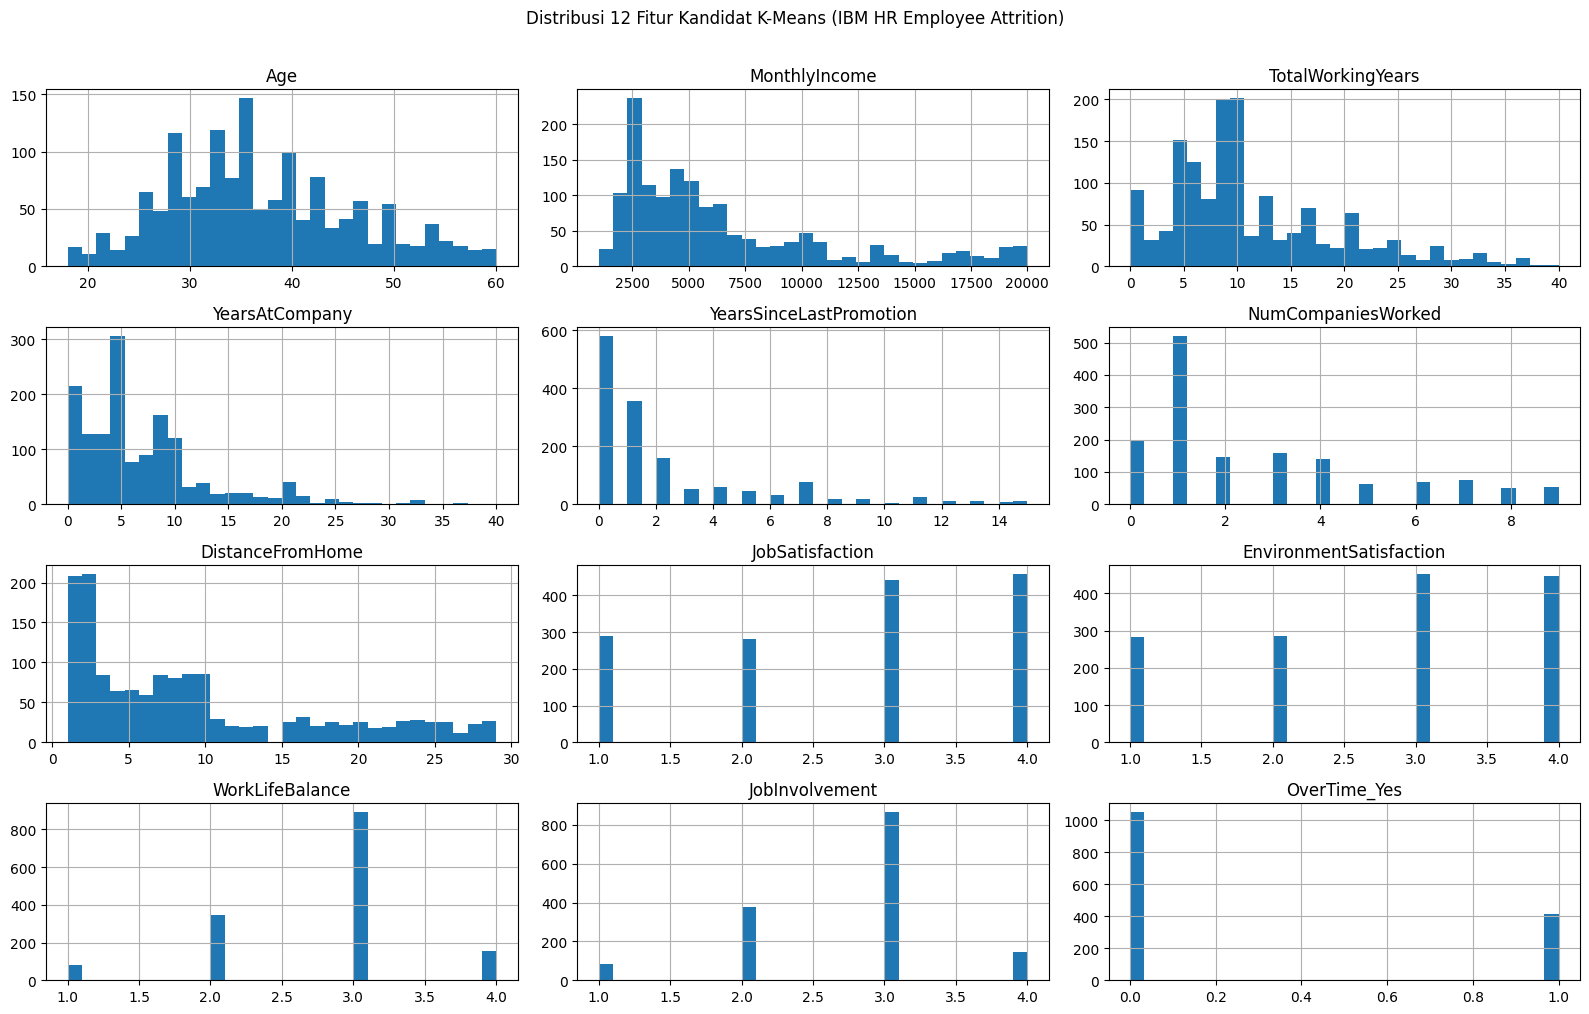

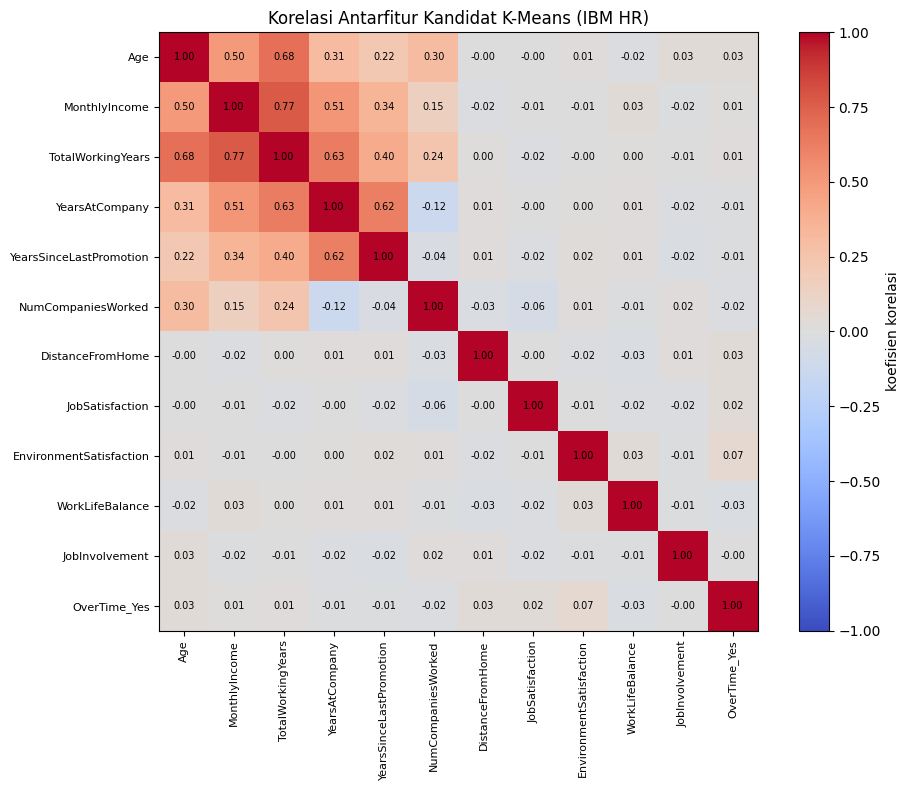

Pasangan berkorelasi > 0,9 pada fitur numerik mentah: [('JobLevel', 'MonthlyIncome', 0.95)]
Pasangan berkorelasi > 0,9 pada 12 fitur kandidat   : tidak ada
Catatan: JobLevel (r=0,950 dengan MonthlyIncome) sudah disisihkan ke bahan interpretasi.


In [20]:
# Grafik 1: Distribusi 12 fitur kandidat
df_eda.hist(figsize=(16, 10), bins=30)
plt.suptitle('Distribusi 12 Fitur Kandidat K-Means (IBM HR Employee Attrition)', y=1.01)
plt.tight_layout(); plt.savefig('gambar/eda_distribusi.png', dpi=110); plt.show()

# Grafik 2: Peta korelasi 12 fitur kandidat
kor = df_eda.corr()
plt.figure(figsize=(10, 8))
plt.imshow(kor, cmap='coolwarm', vmin=-1, vmax=1)
plt.colorbar(label='koefisien korelasi')
plt.xticks(range(len(kor)), kor.columns, rotation=90, fontsize=8)
plt.yticks(range(len(kor)), kor.columns, fontsize=8)
for i in range(len(kor)):
    for j in range(len(kor)):
        plt.text(j, i, f'{kor.iloc[i, j]:.2f}', ha='center', va='center', fontsize=7)
plt.title('Korelasi Antarfitur Kandidat K-Means (IBM HR)')
plt.tight_layout()
plt.savefig('gambar/eda_korelasi.png', dpi=110); plt.show()

# Pemeriksaan korelasi > 0,9 pada seluruh numerik mentah (tanpa ID & konstan) dan pada 12 fitur kandidat
num_mentah = df_mentah.drop(columns=['EmployeeNumber', 'EmployeeCount', 'StandardHours'], errors='ignore').select_dtypes(include=np.number)
kor_mentah = num_mentah.corr()
tinggi_mentah = [(a, b, round(float(kor_mentah.loc[a, b]), 3))
                 for i, a in enumerate(num_mentah.columns) for b in num_mentah.columns[i+1:]
                 if abs(kor_mentah.loc[a, b]) > 0.9]

kolom_eda = df_eda.columns.tolist()
tinggi_eda = [(a, b, round(float(kor.loc[a, b]), 3))
              for i, a in enumerate(kolom_eda) for b in kolom_eda[i+1:]
              if abs(kor.loc[a, b]) > 0.9]

print('Pasangan berkorelasi > 0,9 pada fitur numerik mentah:', tinggi_mentah if tinggi_mentah else 'tidak ada')
print('Pasangan berkorelasi > 0,9 pada 12 fitur kandidat   :', tinggi_eda if tinggi_eda else 'tidak ada')
print('Catatan: JobLevel (r=0,950 dengan MonthlyIncome) sudah disisihkan ke bahan interpretasi.')

## 1.6 Empat jawaban yang dinilai

Keempat jawaban ini masuk ke laporan dan ditanyakan saat Progres 1.

1. **Satu baris data pada dataset ini mewakili apa?**
   Satu baris data mewakili **satu orang karyawan unik**. Hal ini terverifikasi karena dataset memiliki tepat **1.470 baris** dan kolom identitas `EmployeeNumber` memiliki **1.470 nilai unik** (0 baris duplikat identik dan 0 `EmployeeNumber` berulang), sehingga tidak diperlukan proses agregasi baris terlebih dahulu.

2. **Dua kolom dengan skala paling jauh berbeda, beserta min dan max-nya:**
   Pada 12 fitur kandidat segmentasi, dua kolom dengan perbedaan skala paling jauh adalah **`MonthlyIncome`** (`min = 1.009`, `max = 19.999`, standar deviasi `4.707,96`) dan **`OverTime_Yes`** (`min = 0`, `max = 1`, standar deviasi `0,45`), dengan rasio nilai maksimum mencapai **19.999 kali** (dan rasio standar deviasi **10.448 kali**). Karena K-Means menghitung jarak Euclidean, penskalaan dengan `StandardScaler` wajib diterapkan pada tahap pemodelan agar fitur pendapatan tidak mendominasi fitur berskala kecil.

3. **Kolom mana yang dibuang karena berupa identitas, dan mengapa?**
   Kolom **`EmployeeNumber`** dipisahkan dan tidak dijadikan fitur pembentuk klaster karena hanya berfungsi sebagai nomor pengenal unik tiap karyawan (1.470 nilai unik), bukan ukuran karakteristik atau pengalaman kerja. Bila tetap dimasukkan ke K-Means, selisih nomor urut karyawan akan dihitung sebagai jarak kemiripan yang tidak bermakna. Selain itu, tiga kolom konstan (`EmployeeCount`, `StandardHours`, dan `Over18`) juga dibuang karena hanya memiliki 1 nilai unik dan tidak memberi informasi pembeda.

4. **Adakah fitur yang nilainya justru merupakan jawaban yang ingin dicari?**
   Kolom **`Attrition`** (`Yes/No`) merupakan label status keluar/bertahannya karyawan sehingga **tidak dimasukkan** ke fitur pembentuk klaster. Karena K-Means adalah metode tanpa label (*unsupervised*), mengikutsertakan `Attrition` dapat mengarahkan klaster meniru label target tersebut alih-alih menemukan kelompok alami berdasarkan karakteristik kerja. Kolom `Attrition` hanya digunakan sebagai informasi deskriptif untuk menafsirkan profil klaster setelah segmentasi terbentuk.

## 1.7 Membersihkan

Urutan pembersihan pada dataset IBM HR Employee Attrition:
1. Buang baris duplikat.
2. Pisahkan kolom identitas (`EmployeeNumber`) dan format menjadi teks (`EMP_*`) saat disimpan kembali agar tidak pernah terdeteksi sebagai fitur numerik.
3. Buang tiga kolom konstan (`EmployeeCount`, `StandardHours`, `Over18`), turunkan fitur biner `OverTime_Yes` (0/1), lalu pilih 12 fitur kandidat sesuai proposal (memisahkan label `Attrition`, kolom kategori interpretasi, tiga kolom tarif tak terverifikasi, serta `JobLevel` yang berkorelasi `0,950` dengan `MonthlyIncome`).
4. Jalankan imputasi median untuk nilai hilang (bila ada).
5. **Batasi (*clipping*)** pencilan dengan metode IQR 1,5 tanpa menghapus baris.

Pencilan **dibatasi, bukan dibuang**. Pada data kepegawaian, karyawan dengan pendapatan atau masa kerja sangat tinggi merupakan bagian sah dari segmen senior yang tetap ingin dianalisis. Membatasi nilainya menahan tarikan ekstrem terhadap pusat klaster tanpa menghilangkan baris karyawan tersebut.

In [21]:
df = df_mentah.copy()

# 1. Buang duplikat
sebelum = len(df)
df = df.drop_duplicates().reset_index(drop=True)
print(f'Duplikat dibuang: {sebelum - len(df)} baris')

# 2. Pisahkan kolom identitas
ids = None
if ID_COL in df.columns:
    # Diformat sebagai teks ('EMP_1', dst.) agar aman saat dibaca alat.muat_bersih()
    ids = 'EMP_' + df[ID_COL].astype(str)
    df = df.drop(columns=[ID_COL])
    print(f'Kolom identitas {ID_COL} dipisahkan (disimpan sebagai label teks EMP_*)')

# 3. Buang kolom konstan, bentuk fitur biner OverTime_Yes, dan pilih 12 fitur kandidat
kolom_konstan = ['EmployeeCount', 'StandardHours', 'Over18']
df = df.drop(columns=[c for c in kolom_konstan if c in df.columns])
print('Kolom konstan dibuang:', kolom_konstan)

df['OverTime_Yes'] = (df['OverTime'] == 'Yes').astype(int)
kolom_disisihkan = [c for c in df.columns if c not in FITUR_KANDIDAT]
df = df[FITUR_KANDIDAT].copy()
print(f'Kolom non-fitur/interpretasi disisihkan: {len(kolom_disisihkan)} kolom (termasuk Attrition & JobLevel)')
print(f'Jumlah fitur klastering: {len(df.columns)} -> {df.columns.tolist()}')

# 4. Imputasi median (dijalankan tetap konsisten untuk memastikan 0 nilai hilang)
kolom = df.columns.tolist()
print('\nImputasi median:')
total_imputasi = 0
for c in kolom:
    n = int(df[c].isna().sum())
    if n:
        total_imputasi += n
        med = float(df[c].median())
        df[c] = df[c].fillna(med)
        print(f'  {c:<34} {n:>5} nilai -> median {med:,.2f}')
if total_imputasi == 0:
    print('  0 nilai hilang -> tidak ada nilai yang diimputasi')

# 5. Pembatasan pencilan dengan IQR 1,5 (bukan dibuang)
total = 0
print(f'\nPencilan dibatasi dengan IQR {IQR_PENGALI} (bukan dibuang):')
for c in kolom:
    q1, q3 = df[c].quantile(0.25), df[c].quantile(0.75)
    iqr = q3 - q1
    bawah, atas = q1 - IQR_PENGALI * iqr, q3 + IQR_PENGALI * iqr
    kena = int(((df[c] < bawah) | (df[c] > atas)).sum())
    if kena:
        total += kena
        df[c] = df[c].clip(bawah, atas)
        print(f'  {c:<34} {kena:>5} nilai ({kena/len(df)*100:5.2f}%)  [batas: {bawah:.1f} s.d. {atas:.1f}]')
print('Total nilai dibatasi:', total)
print('Bila satu kolom lebih dari 25% nilainya dibatasi, periksa apakah')
print('struktur klasternya masih ada. Bila Silhouette anjlok, naikkan IQR_PENGALI.')

Duplikat dibuang: 0 baris
Kolom identitas EmployeeNumber dipisahkan (disimpan sebagai label teks EMP_*)
Kolom konstan dibuang: ['EmployeeCount', 'StandardHours', 'Over18']
Kolom non-fitur/interpretasi disisihkan: 20 kolom (termasuk Attrition & JobLevel)
Jumlah fitur klastering: 12 -> ['Age', 'MonthlyIncome', 'TotalWorkingYears', 'YearsAtCompany', 'YearsSinceLastPromotion', 'NumCompaniesWorked', 'DistanceFromHome', 'JobSatisfaction', 'EnvironmentSatisfaction', 'WorkLifeBalance', 'JobInvolvement', 'OverTime_Yes']

Imputasi median:
  0 nilai hilang -> tidak ada nilai yang diimputasi

Pencilan dibatasi dengan IQR 1.5 (bukan dibuang):
  MonthlyIncome                        114 nilai ( 7.76%)  [batas: -5291.0 s.d. 16581.0]
  TotalWorkingYears                     63 nilai ( 4.29%)  [batas: -7.5 s.d. 28.5]
  YearsAtCompany                       104 nilai ( 7.07%)  [batas: -6.0 s.d. 18.0]
  YearsSinceLastPromotion              107 nilai ( 7.28%)  [batas: -4.5 s.d. 7.5]
  NumCompaniesWorked     

## 1.8 Menyimpan dan membagikan data bersih

In [22]:
keluar = df.copy()
if ids is not None:
    keluar.insert(0, ID_COL, ids.to_numpy())
keluar.to_csv('data/data_bersih.csv', index=False)
print('Tersimpan: data/data_bersih.csv', keluar.shape)

# Verifikasi langsung dengan fungsi bersama alat.muat_bersih()
import importlib, alat
importlib.reload(alat)
cek_fitur = alat.muat_bersih()
print('Verifikasi alat.muat_bersih():', cek_fitur.shape, '| NaN:', int(cek_fitur.isna().sum().sum()))
assert cek_fitur.shape == (len(df_mentah), len(FITUR_KANDIDAT)), 'Ukuran fitur tidak sesuai!'
assert ID_COL not in cek_fitur.columns, 'Kolom identitas masih terbaca sebagai fitur!'
assert all(cek_fitur[c].nunique() > 1 for c in cek_fitur.columns), 'Ada kolom menjadi konstan setelah clipping!'

from google.colab import files
files.download('data/data_bersih.csv')
files.download('gambar/eda_distribusi.png')
files.download('gambar/eda_korelasi.png')
print()
print('Langkah berikutnya:')
print('  1. Pastikan kedua anggota lain sudah diberi akses Editor pada folder Drive kelompok.')
print('  2. Commit data/raw.csv dan data/data_bersih.csv ke folder data/ pada repositori kelompok.')
print('  3. Commit kedua gambar ke folder gambar/.')
print('  4. Unduh notebook ini: File -> Download -> Download .ipynb,')
print('     beri nama 01_penyiapan_data.ipynb, commit ke folder notebook/.')

Tersimpan: data/data_bersih.csv (1470, 13)
Verifikasi alat.muat_bersih(): (1470, 12) | NaN: 0


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


Langkah berikutnya:
  1. Pastikan kedua anggota lain sudah diberi akses Editor pada folder Drive kelompok.
  2. Commit data/raw.csv dan data/data_bersih.csv ke folder data/ pada repositori kelompok.
  3. Commit kedua gambar ke folder gambar/.
  4. Unduh notebook ini: File -> Download -> Download .ipynb,
     beri nama 01_penyiapan_data.ipynb, commit ke folder notebook/.


## 1.9 Pernyataan urutan kerja

Ini salah satu luaran yang dinilai. Salin paragraf berikut ke `README.md`, **periksa kebenarannya terhadap yang benar-benar Anda jalankan**, lalu sesuaikan bila berbeda.

> Pada cabang klastering tidak ada pemisahan data latih dan data uji, karena tidak ada label target yang diuji. Pembersihan dilakukan satu kali atas seluruh 1.470 baris data: pemeriksaan duplikat (0 baris dibuang), pemisahan kolom identitas `EmployeeNumber` (diformat sebagai teks `EMP_*` agar tidak terbaca sebagai fitur numerik), pembuangan tiga kolom konstan (`EmployeeCount`, `StandardHours`, `Over18`), konversi biner `OverTime` menjadi `OverTime_Yes` (0/1), pemilihan 12 fitur kandidat sesuai proposal (dengan menyisihkan label `Attrition`, atribut kategori interpretasi, tiga kolom tarif tak terverifikasi, serta `JobLevel` yang berkorelasi `0,950` dengan `MonthlyIncome`), pemeriksaan nilai hilang (0 nilai diimputasi), lalu pembatasan pencilan (*clipping*) dengan IQR 1,5 pada 440 nilai ekstrem di 5 fitur numerik tanpa menghapus baris observasi. Hasilnya disimpan sebagai `data/data_bersih.csv` (1.470 baris, 12 fitur numerik + 1 kolom identitas teks) dan dipakai ketiga varian apa adanya. Penskalaan tidak dilakukan pada tahap pembersihan, melainkan di dalam tiap varian dan sekali lagi saat model final dilatih: `StandardScaler` di-*fit* satu kali pada data bersih, lalu disimpan sebagai `scaler.pkl` dan dipakai aplikasi web dengan `transform`, bukan `fit_transform`.

**Mengapa berbeda dari cabang klasifikasi.** Pada k-NN urutan wajibnya adalah bersihkan, pisahkan data, baru skalakan — penskalaan sebelum pemisahan membuat statistik data uji bocor ke pelatihan. Pada klastering tidak ada pemisahan, sehingga yang dijaga bukan kebocoran antar-himpunan, melainkan **kesamaan skala antara notebook dan aplikasi web**.

## Checklist Bagian 1

- [x] `data/raw.csv` ada dan tidak pernah diubah lagi
- [x] `data/data_bersih.csv` ada sebagai berkas di repositori, bukan hanya sel notebook
- [x] `gambar/eda_distribusi.png` dan `gambar/eda_korelasi.png` ter-commit
- [x] Empat jawaban di 1.6 sudah diperiksa dan ditulis dengan kalimat sendiri
- [x] Pernyataan urutan kerja sudah masuk `README.md` dan sudah diperiksa
- [x] Folder Drive `MyDrive/ProyekML_KlasteringKMeans` sudah dibagikan ke kedua anggota lain dengan akses Editor
- [x] Versi `scikit-learn` sudah dicatat untuk `requirements.txt`
- [x] Mulai sekarang tidak ada lagi yang membersihkan data sendiri-sendiri